In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [2]:
daily = pd.read_csv('../data/day.csv')
hrly = pd.read_csv('../data/hour.csv')

In [3]:
print('Daily dataset: ', daily.shape)
print('Hourly datase: ', hrly.shape)

Daily dataset:  (731, 16)
Hourly datase:  (17379, 17)


In [4]:
daily.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [5]:
display(daily.head())

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [6]:
hrly.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [7]:
daily.info()
hrly.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (tot

In [8]:
print(daily.columns.tolist())
print(hrly.columns.tolist())

['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [9]:
#missing values examination
daily.isna().sum()
hrly.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [10]:
hrly.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

#Dteday is the only column with object dtype; this wil bwe cinverted to datetime



In [15]:
#Checking for duplicate rows
daily.duplicated().sum()

0

In [17]:
hrly.duplicated().sum()

0

no duplicates found in eitheer dataset

In [18]:
#building intuition
daily.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000000,211.165812,1.000000,183.500000,366.000000,548.500000,731.000000
season,731.0,2.496580,1.110807,1.000000,2.000000,3.000000,3.000000,4.000000
yr,731.0,0.500684,0.500342,0.000000,0.000000,1.000000,1.000000,1.000000
mnth,731.0,6.519836,3.451913,1.000000,4.000000,7.000000,10.000000,12.000000
holiday,731.0,0.028728,0.167155,0.000000,0.000000,0.000000,0.000000,1.000000
weekday,731.0,2.997264,2.004787,0.000000,1.000000,3.000000,5.000000,6.000000
workingday,731.0,0.683995,0.465233,0.000000,0.000000,1.000000,1.000000,1.000000
weathersit,731.0,1.395349,0.544894,1.000000,1.000000,1.000000,2.000000,3.000000
temp,731.0,0.495385,0.183051,0.059130,0.337083,0.498333,0.655417,0.861667
atemp,731.0,0.474354,0.162961,0.079070,0.337842,0.486733,0.608602,0.840896


In [19]:
hrly.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


hum, atemp, temp, is bw 0 and 1,  workingday, holiday,yr has 2 vals(0 or 1), season 1 to 4, 

In [20]:
print(daily.columns.tolist())
print(hrly.columns.tolist())

['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [21]:
#understanding the target var
daily[['casual', 'registered', 'cnt']].describe().T

,count,mean,std,min,25%,50%,75%,max
casual,731.0,848.176471,686.622488,2.0,315.5,713.0,1096.0,3410.0
registered,731.0,3656.172367,1560.256377,20.0,2497.0,3662.0,4776.5,6946.0
cnt,731.0,4504.348837,1937.211452,22.0,3152.0,4548.0,5956.0,8714.0


In [22]:
hrly[['casual', 'registered', 'cnt']].describe().T

,count,mean,std,min,25%,50%,75%,max
casual,17379.0,35.676218,49.305030,0.0,4.0,17.0,48.0,367.0
registered,17379.0,153.786869,151.357286,0.0,34.0,115.0,220.0,886.0
cnt,17379.0,189.463088,181.387599,1.0,40.0,142.0,281.0,977.0


In [24]:
print('Daily Total: ', daily['cnt'].sum())
print('Hrly total: ', hrly['cnt'].sum())

Daily Total:  3292679
Hrly total:  3292679


<Axes: >

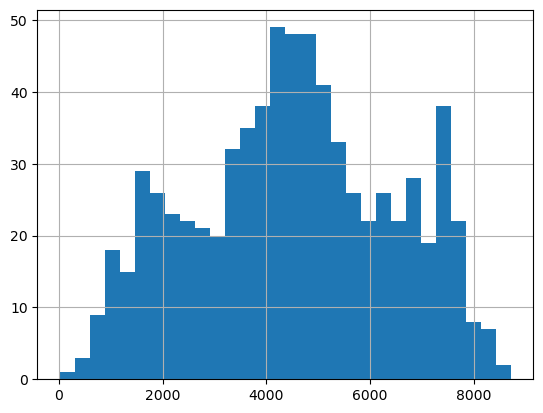

In [25]:
# verifying rental demand distribution
daily['cnt'].hist(bins = 30)

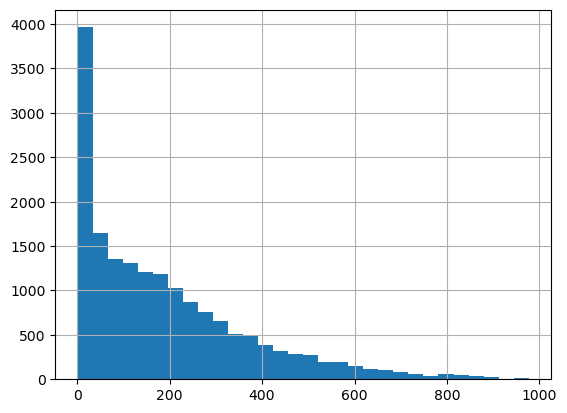

In [26]:
hrly['cnt'].hist(bins = 30);

hrly rentals is heavily left skewed but daily has a somewhat normal distribution though not perfectly normal

In [27]:
# verifying the distribution
daily['cnt'].skew()

-0.04735278011900183

In [28]:
hrly['cnt'].skew()

1.2774116037490577

In [29]:
#verify relationship bw target and components
daily[['casual', 'registered', 'cnt']].describe()

,casual,registered,cnt
count,731.000000,731.000000,731.000000
mean,848.176471,3656.172367,4504.348837
std,686.622488,1560.256377,1937.211452
min,2.000000,20.000000,22.000000
25%,315.500000,2497.000000,3152.000000
50%,713.000000,3662.000000,4548.000000
75%,1096.000000,4776.500000,5956.000000
max,3410.000000,6946.000000,8714.000000


In [30]:
#seasonal analysis
daily.groupby('season')['cnt'].mean()

season
1    2604.132597
2    4992.331522
3    5644.303191
4    4728.162921
Name: cnt, dtype: float64

highest demand is in autumn while the lowest is in spring. summer has slightly moer rentals than winter

In [31]:
#By weather
daily.groupby('weathersit')['cnt'].mean()

weathersit
1    4876.786177
2    4035.862348
3    1803.285714
Name: cnt, dtype: float64

peak rentals is in clear/partly cloudy weather, mist/cloudly has a healthey amount of rentals. but during light rain/snow, the amount of rentals plummets

In [33]:
#wroking day vs weekday?
daily.groupby('workingday')['cnt'].mean()

workingday
0    4330.168831
1    4584.820000
Name: cnt, dtype: float64

daily demands maintain the same trend regardless of whether its a working day or not. workingday has slighlty better performance

In [34]:
#examining hrly demand patterns
hrly.groupby('hr')['cnt'].mean()

hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64

Bike demand peaks during work hours; in the morning by 8am(359) and at close of work by 5pm to wards 6 (461, 425)

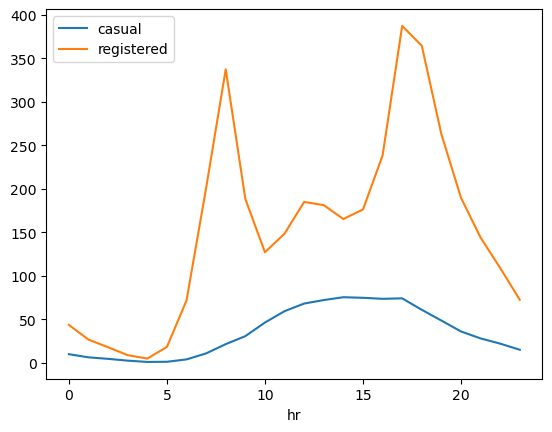

In [36]:
#comparing casual and registered users by hr
hrly.groupby('hr')[['casual', 'registered']].mean().plot();

the usage bu registered users is what primarily drives up demand during rush hours. the casual users demand peak in the afteroon around the hours of 3

In [37]:
# comparing demand across weekday
hrly.groupby('weekday')['cnt'].mean()

weekday
0    177.468825
1    183.744655
2    191.238891
3    191.130505
4    196.436665
5    196.135907
6    190.209793
Name: cnt, dtype: float64

average hrly demand on weekdays is fairly stable. the demand drops on sunday rhen increases on mondayb4 stabilising on tuesday

In [38]:
#examining correlations
daily.corr(numeric_only = True)['cnt'].sort_values(ascending = False)

cnt           1.000000
registered    0.945517
casual        0.672804
atemp         0.631066
instant       0.628830
temp          0.627494
yr            0.566710
season        0.406100
mnth          0.279977
weekday       0.067443
workingday    0.061156
holiday      -0.068348
hum          -0.100659
windspeed    -0.234545
weathersit   -0.297391
Name: cnt, dtype: float64

season and mnth are cats so the corr might be misleading b4 encoding, registered and casual are fxns of cnt so the high corr values are functions of maths

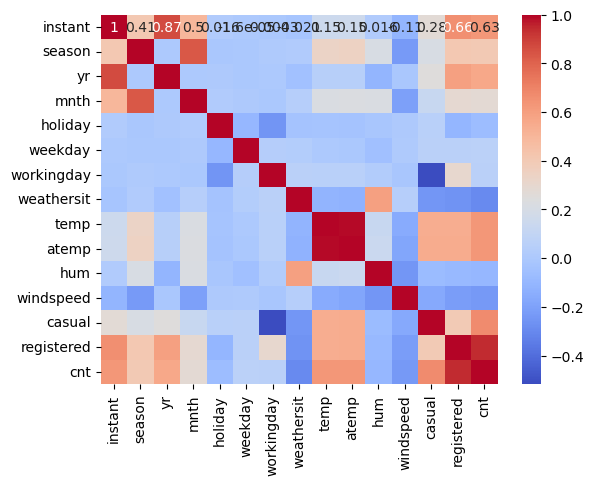

In [39]:
sns.heatmap(daily.corr(numeric_only = True), annot = True, cmap = 'coolwarm')
plt.show();

### Feature Engineering

In [41]:
# converting dteday to datetime
daily['dteday'] = pd.to_datetime(daily['dteday'])

daily['dteday'].dtype

dtype('<M8[ns]')

In [42]:
daily['year'] = daily['dteday'].dt.year
daily['month'] = daily['dteday'].dt.month
daily['day'] = daily['dteday'].dt.day

daily[['dteday', 'year', 'month', 'day']].head()

,dteday,year,month,day
0,2011-01-01,2011,1,1
1,2011-01-02,2011,1,2
2,2011-01-03,2011,1,3
3,2011-01-04,2011,1,4
4,2011-01-05,2011,1,5


In [43]:
daily.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
 16  year        731 non-null  

In [44]:
#inspecting hrly dataset 
hrly['dteday'] = pd.to_datetime(hrly['dteday'])

hrly['year'] = hrly['dteday'].dt.year
hrly['month'] = hrly['dteday'].dt.month
hrly['day'] = hrly['dteday'].dt.day


In [45]:
hrly[['dteday', 'year', 'month', 'day']]

,dteday,year,month,day
0,2011-01-01,2011,1,1
1,2011-01-01,2011,1,1
2,2011-01-01,2011,1,1
3,2011-01-01,2011,1,1
4,2011-01-01,2011,1,1
...,...,...,...,...
17374,2012-12-31,2012,12,31
17375,2012-12-31,2012,12,31
17376,2012-12-31,2012,12,31
17377,2012-12-31,2012,12,31


In [46]:
daily[['year', 'month', 'day', 'cnt']].head(10)

,year,month,day,cnt
0,2011,1,1,985
1,2011,1,2,801
2,2011,1,3,1349
3,2011,1,4,1562
4,2011,1,5,1600
5,2011,1,6,1606
6,2011,1,7,1510
7,2011,1,8,959
8,2011,1,9,822
9,2011,1,10,1321


`casual` and `registered` are components of the target `cnt` so leads to data leakage; `instant` is a record identiier not demand driver so will be dropped too `dteday` will be used only to slice data.

In [47]:
daily.columns.tolist()

['instant',
 'dteday',
 'season',
 'yr',
 'mnth',
 'holiday',
 'weekday',
 'workingday',
 'weathersit',
 'temp',
 'atemp',
 'hum',
 'windspeed',
 'casual',
 'registered',
 'cnt',
 'year',
 'month',
 'day']

In [48]:
x = daily.drop(columns = ['instant', 'dteday', 'casual', 'registered', 'cnt'])
y = daily['cnt']

In [49]:
x.shape, y.shape

((731, 14), (731,))

In [50]:
x.select_dtypes(include = 'number').columns


Index(['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'year', 'month',
       'day'],
      dtype='object')

In [51]:
continuous = ['temp', 'atemp', 'hum', 'windspeed']

In [53]:
#sorting chronologically
daily = daily.sort_values('dteday')

In [54]:
#Splitting data
split_index = int(len(daily) * 0.8)

x_train = x.iloc[:split_index]
x_test = x.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [55]:
#Verifying the split
x_train.shape, x_test.shape

((584, 14), (147, 14))

In [56]:
#Establishing a baseline model
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline = DummyRegressor(strategy = 'mean')
baseline.fit(x_train, y_train)

baseline_pred = baseline.predict(x_test)

In [57]:
print('MAE: ', mean_absolute_error(y_test, baseline_pred))

print('RMSE: ', np.sqrt(mean_squared_error(y_test, baseline_pred)))

print('R2: ', r2_score(y_test, baseline_pred))

MAE:  2290.4127061783615
RMSE:  2560.5558481236217
R2:  -0.8657005548327481


In [58]:
#using linear predictive model
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline 
from sklearn.linear_model import LinearRegression

In [59]:
continuous = ['temp', 'hum', 'windspeed']
categories = ['season', 'mnth', 'weekday', 'weathersit']
binary = ['yr', 'holiday', 'workingday']

# atemp excluded cause its perfectly correlated with temp, year and month cause its duplicated with yr and mnht, day cause day of month isn't actually a meanungful predictor on its own

preprocessor = ColumnTransformer([('num', StandardScaler(), continuous),
                                  ('cat', OneHotEncoder(handle_unknown = 'ignore'), categories),
                                  ('bin', 'passthrough', binary)
])

lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

In [61]:
#training
lr_model.fit(x_train, y_train)
lr_pred = lr_model.predict(x_test)

In [62]:
#Evaluation
print('MAE: ', mean_absolute_error(y_test, lr_pred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, lr_pred)))
print('R2: ', r2_score(y_test, lr_pred))

MAE:  804.4610955228524
RMSE:  1103.6668642945851
R2:  0.6533833320855447


In [63]:
from sklearn.ensemble import RandomForestRegressor

rfmodel = RandomForestRegressor(
    n_estimators = 100,
    random_state = 42,
    n_jobs = -1
)

rfmodel.fit(x_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [64]:
rf_pred = rfmodel.predict(x_test)


In [65]:
#Evaluate
print('MAE: ', mean_absolute_error(y_test, rf_pred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, rf_pred)))
print('R2: ', r2_score(y_test, rf_pred))

MAE:  911.8006122448979
RMSE:  1114.70707189985
R2:  0.6464140919410952


In [66]:
#which variables contribute most to prediction (FEATURE IMPORTANCE)

importance = pd.Series(rfmodel.feature_importances_, index = x_train.columns).sort_values(ascending = False)

print(importance)

temp          0.292247
atemp         0.261800
year          0.130865
yr            0.115360
hum           0.058548
season        0.042797
windspeed     0.025523
weathersit    0.019758
day           0.013037
mnth          0.012668
month         0.011849
weekday       0.010345
workingday    0.003347
holiday       0.001855
dtype: float64


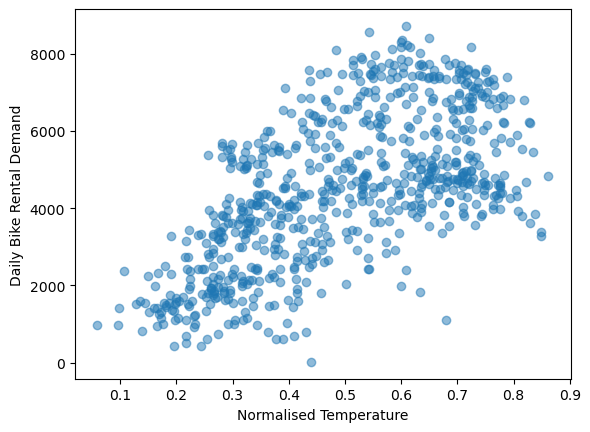

In [67]:
#just how important is temperature and which direction?

plt.scatter(daily['temp'],
            daily['cnt'], alpha = 0.5)
plt.xlabel('Normalised Temperature')
plt.ylabel('Daily Bike Rental Demand')
plt.show();

 the wide spread tells us temperature alone is not enough to forecast demand

In [68]:
daily['temp'].corr(daily['cnt'])

0.6274940090334918

In [69]:
daily['atemp'].corr(daily['cnt'])

0.6310656998491811

In [70]:
##Hyperparameter tuning

for n in [50, 100, 200, 300]:
    model = RandomForestRegressor(
        n_estimators = n,
        random_state = 42,
        n_jobs = -1
    )

    model.fit(x_train, y_train)
    pred = model.predict(x_test)

    print(n, 
          mean_absolute_error(y_test, pred),
          np.sqrt(mean_squared_error(y_test, pred)),
          r2_score(y_test, pred)
        )
    

50 902.66231292517 1111.4849469874036 0.6484552584297203
100 911.8006122448979 1114.70707189985 0.6464140919410952
200 926.3208503401361 1125.660617958761 0.639431004585912
300 924.6437641723356 1124.5057246955957 0.6401704905031802


In [71]:
#toggling the max depth
for depth in [5, 10, 15, 20, None]:
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth = depth,
        random_state = 42,
        n_jobs = -1
    )

    model.fit(x_train, y_train)
    pred = model.predict(x_test)

    print(
        depth,
        mean_absolute_error(y_test, pred),
        np.sqrt(mean_squared_error(y_test, pred)),
        r2_score(y_test, pred)
    )

5 984.6760261161184 1171.4804453205825 0.609479782376831
10 917.1195000004822 1116.9359401899392 0.6449986809481252
15 906.7619308353211 1109.7463993645824 0.649554147415828
20 911.4425850340136 1114.337338681421 0.6466486123419818
None 911.8006122448979 1114.70707189985 0.6464140919410952


In [72]:
for split in [2, 5, 10, 20, 30]:
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth = 15,
        min_samples_split=split,
        random_state=42,
        n_jobs = -1
    )

    model.fit(x_train, y_train)
    pred = model.predict(x_test)

    print(
        split,
        mean_absolute_error(y_test, pred),
        np.sqrt(mean_squared_error(y_test, pred)),
        r2_score(y_test, pred)
    )

2 906.7619308353211 1109.7463993645824 0.649554147415828
5 895.2682529591534 1096.5885973061015 0.6578150640205089
10 886.7182250097733 1097.0265803727966 0.6575416686237905
20 928.3294551627034 1149.702586998149 0.6238643890356872
30 996.2048899522825 1213.0611637966902 0.5812654141699138


In [73]:
#Comparing/testing for overfitting in RF
best_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth = 15,
    min_samples_split= 10,
    random_state=42,
    n_jobs = -1
)

best_rf.fit(x_train, y_train)
train_pred = best_rf.predict(x_train)
test_pred = best_rf.predict(x_test)

print('Train R2: ', r2_score(y_train, train_pred))
print('Test R2: ', r2_score(y_test, test_pred))

Train R2:  0.9603078197368999
Test R2:  0.6575416686237905


this tells us that the model has extremely overfitted on the train data

In [75]:
# using min_sampes_leaf to stem overfitting
for leaf in [1, 2, 5, 10, 15, 20]:
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1
    )

    model.fit(x_train, y_train)
    pred = model.predict(x_test)

    print(
        leaf,
        mean_absolute_error(y_test, pred),
        np.sqrt(mean_squared_error(y_test, pred)),
        r2_score(y_test, pred)
    )

1 886.7182250097734 1097.0265803727966 0.6575416686237905
2 896.5446194575217 1111.4338836986976 0.6484875586751386
5 938.561681426809 1149.4692471209032 0.6240170520492121
10 1039.5043891826808 1253.6825375055296 0.5527518130869861
15 1089.5546758190533 1300.4443235083697 0.5187652702334633
20 1142.2889022009829 1354.142078211199 0.4782026102155815


increasing number of leaf size restricts the tree's flexibility; crossvalidating the model now

In [77]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

tscv = TimeSeriesSplit(n_splits = 5)

cv_scores = cross_val_score(
    best_rf,
    x_train,
    y_train,
    cv = tscv,
    scoring = 'r2',
    n_jobs = -1
)

print('CV scores: ', cv_scores)
print('Mean R2: ',cv_scores.mean())
print('Std R2: ', cv_scores.std())

CV scores:  [-3.12440813  0.21482439 -0.75100782 -0.62499929  0.06786876]
Mean R2:  -0.8435444211874883
Std R2:  1.2007899721125403


In [78]:
## Investigating thr fold result

for train_idx, val_idx in tscv.split(x_train):
    print(
        'Train', train_idx[0], '-', train_idx[-1],
        '|validation: ', val_idx[0], '-', val_idx[-1]
    )

Train 0 - 98 |validation:  99 - 195
Train 0 - 195 |validation:  196 - 292
Train 0 - 292 |validation:  293 - 389
Train 0 - 389 |validation:  390 - 486
Train 0 - 486 |validation:  487 - 583


The RF though narrowly better than linear regression is overfitted and cross validation showed inconsistent performance so i cant tell if the model generalises reliably acorss the different periods